# LAB 04 — Text Classification
Practical sections 11–23 from W4.pdf using SMS Spam Collection for supervised experiments.

## Setup

In [2]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)
from sklearn.pipeline import Pipeline

from preprocessing import load_sms_spam_dataset, clean_dataframe

RANDOM_STATE = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.10  # Fraction of the full dataset
DATA_PATH = Path("SMSSpamCollection")  # Change to Path("spam.csv") if needed
RESULTS_PATH = Path("results.csv")
CONFUSION_MATRIX_PATH = Path("confusion_matrix.png")

# The expected classes in the SMS Spam Collection dataset are "ham" and "spam".

## Section 11 — Experiment 1: Dataset inspection

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Place the SMS Spam Collection file here or update DATA_PATH."
    )

raw_df = load_sms_spam_dataset(DATA_PATH)
print("Raw shape:", raw_df.shape)
display(raw_df.head())

print("\nMissing values before cleaning:")
print(raw_df[["label", "text"]].isna().sum())

print("\nDuplicate full rows:", raw_df.duplicated(subset=["label", "text"]).sum())
print("Duplicate message texts:", raw_df["text"].duplicated().sum())

df = clean_dataframe(raw_df)
df = df.dropna(subset=["label", "text"]).copy()
df = df[df["text"].str.strip().ne("")].copy()
df = df[df["label"].isin(["ham", "spam"])].copy()
df = df.drop_duplicates(subset=["label", "text"]).reset_index(drop=True)

print("\nShape after basic cleaning and removing duplicate label-text pairs:", df.shape)
print("Number of classes:", df["label"].nunique())
print("Classes:", sorted(df["label"].unique()))

Raw shape: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Missing values before cleaning:
label    0
text     0
dtype: int64

Duplicate full rows: 403
Duplicate message texts: 403

Shape after basic cleaning and removing duplicate label-text pairs: (5157, 2)
Number of classes: 2
Classes: ['ham', 'spam']


,count,percentage
class,,
ham,4515,87.550902
spam,642,12.449098


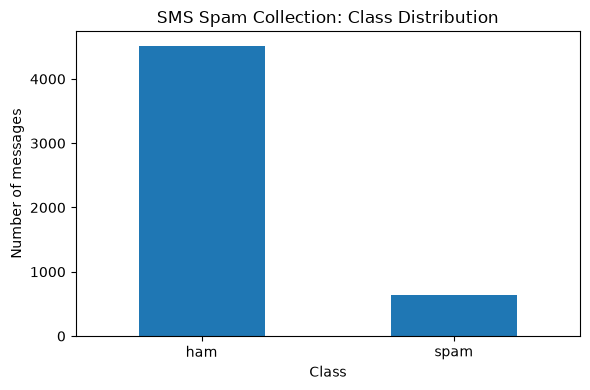

character_length                                                   \
                 count    mean    std   min    25%    50%    75%    max   
label                                                                     
ham             4515.0   70.79  56.60   2.0   34.0   53.0   91.0  910.0   
spam             642.0  137.41  29.98  13.0  131.0  148.0  157.0  223.0   

      word_count                                               
           count   mean    std  min    25%   50%   75%    max  
label                                                          
ham       4515.0  14.24  11.18  1.0   7.00  11.0  19.0  171.0  
spam       642.0  23.70   5.97  2.0  21.25  25.0  28.0   35.0

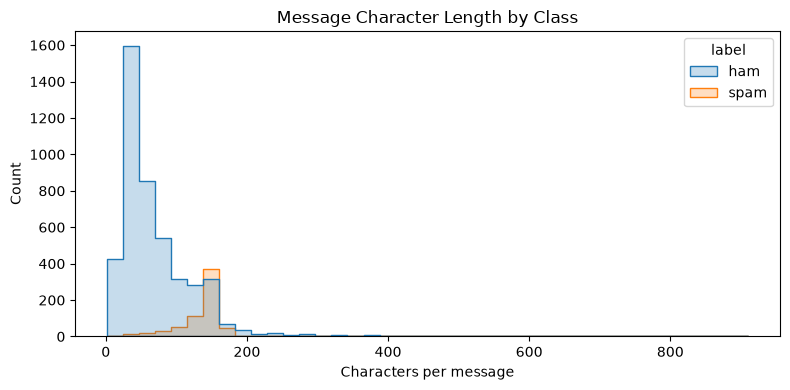

Majority/minority class ratio: 7.033


In [4]:
class_counts = df["label"].value_counts().rename_axis("class").to_frame("count")
class_counts["percentage"] = 100 * class_counts["count"] / len(df)
display(class_counts)

ax = class_counts["count"].plot(kind="bar", rot=0, figsize=(6, 4))
ax.set_title("SMS Spam Collection: Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of messages")
plt.tight_layout()
plt.show()

# Message length inspection
df["character_length"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()
display(df.groupby("label")[["character_length", "word_count"]].describe().round(2))

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="character_length", hue="label", bins=40, element="step", stat="count", common_norm=False)
plt.title("Message Character Length by Class")
plt.xlabel("Characters per message")
plt.tight_layout()
plt.show()

imbalance_ratio = class_counts["count"].max() / class_counts["count"].min()
print("Majority/minority class ratio:", round(float(imbalance_ratio), 3))

### Is this dataset imbalanced?

The class distribution is imbalanced. Ham messages account for 87.55% of the dataset (4,515 messages), while spam messages account for only 12.45% (642 messages). The majority-to-minority class ratio is approximately 7.03:1.

## Section 12 — Data leakage: split before fitting vectorizers

In [5]:
# Split first. The TF-IDF vectorizer will be fitted only on X_train in later cells.
X = df["text"].astype(str)
y = df["label"].astype(str)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

# Validation size is defined relative to the full dataset.
validation_fraction_of_train_val = VALIDATION_SIZE / (1 - TEST_SIZE)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=validation_fraction_of_train_val,
    random_state=RANDOM_STATE,
    stratify=y_train_val,
)

print("Train samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))
print("\nTrain distribution:\n", y_train.value_counts(normalize=True).round(3))
print("\nValidation distribution:\n", y_val.value_counts(normalize=True).round(3))
print("\nTest distribution:\n", y_test.value_counts(normalize=True).round(3))

Train samples: 3609
Validation samples: 516
Test samples: 1032

Train distribution:
 label
ham     0.875
spam    0.125
Name: proportion, dtype: float64

Validation distribution:
 label
ham     0.876
spam    0.124
Name: proportion, dtype: float64

Test distribution:
 label
ham     0.876
spam    0.124
Name: proportion, dtype: float64


### Helper functions — evaluation and results logging

In [6]:
RESULT_COLUMNS = [
    "experiment", "representation", "classifier", "training_time_seconds",
    "vocabulary_size", "accuracy", "precision", "recall", "f1", "notes"
]

def evaluate_predictions(y_true, y_pred):
    """Return common binary classification metrics; spam is the positive class."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label="spam", zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label="spam", zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label="spam", zero_division=0),
    }

def append_result(experiment, representation, classifier, train_seconds,
                  vocabulary_size, metrics, notes=""):
    row = {
        "experiment": experiment,
        "representation": representation,
        "classifier": classifier,
        "training_time_seconds": train_seconds,
        "vocabulary_size": vocabulary_size,
        **metrics,
        "notes": notes,
    }
    row_df = pd.DataFrame([row], columns=RESULT_COLUMNS)
    if RESULTS_PATH.exists() and RESULTS_PATH.stat().st_size > 0:
        existing = pd.read_csv(RESULTS_PATH)
        # Keep only the expected columns and replace an earlier run of the same experiment/model.
        for column in RESULT_COLUMNS:
            if column not in existing.columns:
                existing[column] = np.nan
        existing = existing[RESULT_COLUMNS]
        key = (existing["experiment"] == experiment) & (existing["representation"] == representation) & (existing["classifier"] == classifier)
        existing = existing.loc[~key]
        combined = pd.concat([existing, row_df], ignore_index=True)
    else:
        combined = row_df
    combined.to_csv(RESULTS_PATH, index=False)
    return row

## Section 13–14 — Core implementation and Experiment 2: TF-IDF + Logistic Regression baseline

In [7]:
baseline_vectorizer = TfidfVectorizer(ngram_range=(1, 1), min_df=1)
X_train_tfidf = baseline_vectorizer.fit_transform(X_train)
X_val_tfidf = baseline_vectorizer.transform(X_val)
X_test_tfidf = baseline_vectorizer.transform(X_test)

baseline_model = LogisticRegression(max_iter=1000, class_weight=None, random_state=RANDOM_STATE)

start_time = time.perf_counter()
baseline_model.fit(X_train_tfidf, y_train)
baseline_train_seconds = time.perf_counter() - start_time

baseline_val_pred = baseline_model.predict(X_val_tfidf)
baseline_test_pred = baseline_model.predict(X_test_tfidf)

baseline_val_metrics = evaluate_predictions(y_val, baseline_val_pred)
baseline_test_metrics = evaluate_predictions(y_test, baseline_test_pred)

print("Validation metrics:")
display(pd.DataFrame([baseline_val_metrics]).round(4))
print("Test metrics:")
display(pd.DataFrame([baseline_test_metrics]).round(4))
print("Training time (seconds):", round(baseline_train_seconds, 4))
print("Vocabulary size:", len(baseline_vectorizer.vocabulary_))

append_result(
    experiment="baseline",
    representation="TF-IDF unigram",
    classifier="Logistic Regression",
    train_seconds=baseline_train_seconds,
    vocabulary_size=len(baseline_vectorizer.vocabulary_),
    metrics=baseline_test_metrics,
    notes="Test-set metrics; TF-IDF fitted on training data only",
)

Validation metrics:


,accuracy,precision,recall,f1
0,0.9593,1.0,0.6719,0.8037


Test metrics:


,accuracy,precision,recall,f1
0,0.9622,0.9785,0.7109,0.8235


Training time (seconds): 0.0183
Vocabulary size: 7124


{'experiment': 'baseline',
 'representation': 'TF-IDF unigram',
 'classifier': 'Logistic Regression',
 'training_time_seconds': 0.018256400000154827,
 'vocabulary_size': 7124,
 'accuracy': 0.9622093023255814,
 'precision': 0.978494623655914,
 'recall': 0.7109375,
 'f1': 0.8235294117647058,
 'notes': 'Test-set metrics; TF-IDF fitted on training data only'}

## Section 15 — Experiment 3: Representation / classifier comparison

The Word2Vec experiment below trains embeddings using **training messages only**. It then averages token vectors into one vector per message. This is a simple baseline and is not a pretrained Word2Vec model.

In [8]:
# Optional dependency: gensim
try:
    from gensim.models import Word2Vec
except ImportError as exc:
    raise ImportError("Install gensim to run the Average Word2Vec experiment: pip install gensim") from exc

def tokenize_for_word2vec(text):
    # Keep this tokenizer simple and consistent for the baseline experiment.
    return basic_tokenize(text)

def basic_tokenize(text):
    import re
    return re.findall(r"\b\w+\b", str(text).lower())

train_tokens = [tokenize_for_word2vec(text) for text in X_train]
w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    seed=RANDOM_STATE,
    epochs=20,
)

def average_word2vec(text, model, vector_size=100):
    tokens = tokenize_for_word2vec(text)
    vectors = [model.wv[token] for token in tokens if token in model.wv]
    if not vectors:
        return np.zeros(vector_size, dtype=np.float32)
    return np.mean(vectors, axis=0).astype(np.float32)

X_train_avg = np.vstack([average_word2vec(text, w2v_model) for text in X_train])
X_val_avg = np.vstack([average_word2vec(text, w2v_model) for text in X_val])
X_test_avg = np.vstack([average_word2vec(text, w2v_model) for text in X_test])

w2v_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
start_time = time.perf_counter()
w2v_lr.fit(X_train_avg, y_train)
w2v_train_seconds = time.perf_counter() - start_time

w2v_test_pred = w2v_lr.predict(X_test_avg)
w2v_test_metrics = evaluate_predictions(y_test, w2v_test_pred)

append_result(
    experiment="representation_comparison",
    representation="Average Word2Vec",
    classifier="Logistic Regression",
    train_seconds=w2v_train_seconds,
    vocabulary_size=len(w2v_model.wv),
    metrics=w2v_test_metrics,
    notes="Word2Vec trained on training messages only; test-set metrics",
)

# Optional Model C: TF-IDF + Linear SVM
svm_vectorizer = TfidfVectorizer(ngram_range=(1, 1), min_df=1)
X_train_svm = svm_vectorizer.fit_transform(X_train)
X_test_svm = svm_vectorizer.transform(X_test)
svm_model = LinearSVC(random_state=RANDOM_STATE)

start_time = time.perf_counter()
svm_model.fit(X_train_svm, y_train)
svm_train_seconds = time.perf_counter() - start_time

svm_test_pred = svm_model.predict(X_test_svm)
svm_test_metrics = evaluate_predictions(y_test, svm_test_pred)

append_result(
    experiment="representation_comparison",
    representation="TF-IDF unigram",
    classifier="Linear SVM",
    train_seconds=svm_train_seconds,
    vocabulary_size=len(svm_vectorizer.vocabulary_),
    metrics=svm_test_metrics,
    notes="Optional Model C; test-set metrics",
)

print("Comparison results saved to", RESULTS_PATH.resolve())
display(pd.read_csv(RESULTS_PATH).round(4))

Comparison results saved to C:\Users\ADMIN\NLP_Apps_Labs\lab04\results.csv


,experiment,representation,classifier,training_time_seconds,vocabulary_size,accuracy,precision,recall,f1,notes
0,baseline,TF-IDF unigram,Logistic Regression,0.0183,7124,0.9622,0.9785,0.7109,0.8235,Test-set metrics; TF-IDF fitted on training da...
1,representation_comparison,Average Word2Vec,Logistic Regression,0.0096,7164,0.9767,0.9727,0.8359,0.8992,Word2Vec trained on training messages only; te...
2,representation_comparison,TF-IDF unigram,Linear SVM,0.0081,7124,0.9864,0.9831,0.9062,0.9431,Optional Model C; test-set metrics


## Section 16 — Representation comparison notes

TF-IDF and Average Word2Vec represent text differently. TF-IDF produces sparse vectors because most words in the vocabulary do not appear in a particular message. It preserves lexical information by assigning weights to individual words, which can be useful for spam detection when certain words are strong indicators of spam.

Average Word2Vec produces dense, fixed-size vectors by averaging the embeddings of words in each message. It can capture semantic similarities between words, allowing words with related meanings to have similar representations. However, averaging word embeddings loses word order and may weaken the contribution of important words, such as negation words like "not".

In the experiment, TF-IDF with Logistic Regression achieved an accuracy of 0.9622 and an F1-score of 0.8235. Average Word2Vec with Logistic Regression achieved a higher accuracy of 0.9767 and an F1-score of 0.8992. Its recall was also higher (0.8359 compared with 0.7109), while its precision was slightly lower (0.9727 compared with 0.9785).

## Section 17 — Experiment 4: Word order

In [9]:
# This section deliberately uses the two illustrative sentences from W4.pdf.
example_sentences = [
    "this movie is good",
    "this movie is not good",
]

example_tokens = [tokenize_for_word2vec(text) for text in example_sentences]
example_w2v = Word2Vec(
    sentences=example_tokens,
    vector_size=50,
    window=3,
    min_count=1,
    workers=1,
    sg=1,
    seed=RANDOM_STATE,
    epochs=100,
)

example_vectors = {
    sentence: average_word2vec(sentence, example_w2v, vector_size=50)
    for sentence in example_sentences
}

print("Cosine similarity between averaged sentence vectors:")
from sklearn.metrics.pairwise import cosine_similarity
sentence_vectors = np.vstack([example_vectors[s] for s in example_sentences])
print(float(cosine_similarity(sentence_vectors[0:1], sentence_vectors[1:2])[0, 0]))

# Inspect the contribution of "not" as a standalone token vector.
print('Token "not" vector (first 10 dimensions):', example_w2v.wv["not"][:10])

Cosine similarity between averaged sentence vectors:
0.9059911370277405
Token "not" vector (first 10 dimensions): [-0.00534946  0.01634323 -0.00019737  0.00798828 -0.0017033  -0.0093652
  0.01056918  0.01876705 -0.00945901  0.01115004]


The cosine similarity between the averaged sentence vectors was 0.9060, which indicates that the two sentence representations are highly similar. This can happen because the sentences share most of their words, while the word "not" appears in only one sentence.

The Word2Vec model has a separate embedding for "not", as shown by its non-zero vector values. However, when word embeddings are averaged, each word contributes to a single sentence vector, and the representation does not preserve word order. As a result, the important negation information may be weakened, making the two sentences difficult to distinguish based on their averaged vectors alone.

## Section 18 — Experiment 5: TF-IDF unigram vs unigram + bigram

In [10]:
ngram_experiment_results = []

for name, ngram_range in [
    ("TF-IDF unigram", (1, 1)),
    ("TF-IDF unigram+bigram", (1, 2)),
]:
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, min_df=1)
    Xtr = vectorizer.fit_transform(X_train)
    Xte = vectorizer.transform(X_test)
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

    start_time = time.perf_counter()
    model.fit(Xtr, y_train)
    elapsed = time.perf_counter() - start_time

    pred = model.predict(Xte)
    metrics = evaluate_predictions(y_test, pred)
    append_result(
        experiment="ngram_features",
        representation=name,
        classifier="Logistic Regression",
        train_seconds=elapsed,
        vocabulary_size=len(vectorizer.vocabulary_),
        metrics=metrics,
        notes="Test-set metrics",
    )
    ngram_experiment_results.append({
        "features": name,
        "vocabulary_size": len(vectorizer.vocabulary_),
        "training_time_seconds": elapsed,
        **metrics,
    })

ngram_results_df = pd.DataFrame(ngram_experiment_results)
display(ngram_results_df.round(4))

,features,vocabulary_size,training_time_seconds,accuracy,precision,recall,f1
0,TF-IDF unigram,7124,0.0166,0.9622,0.9785,0.7109,0.8235
1,TF-IDF unigram+bigram,38643,0.0643,0.9564,1.0000,0.6484,0.7867


### Comparison

The TF-IDF unigram model achieved an accuracy of 0.9622 and an F1-score of 0.8235, while the unigram + bigram model achieved an accuracy of 0.9564 and an F1-score of 0.7867. Although adding bigrams allows the model to capture two-word expressions, the results show that it did not improve overall classification performance in this experiment.

The vocabulary size increased from 7,124 to 38,643 features, and training time increased from 0.0166 to 0.0643 seconds. This suggests that bigram features increased the feature space and computational cost.

The unigram + bigram model achieved a higher precision of 1.0000, compared with 0.9785 for unigram. However, its recall decreased from 0.7109 to 0.6484, meaning that it missed more actual spam messages. Consequently, its F1-score was lower.

Overall, TF-IDF unigram performed better in terms of accuracy, recall, F1-score, and training time in this experiment. Adding bigrams improved precision but did not improve the overall balance between precision and recall. Therefore, using more features does not necessarily lead to better classification performance.

## Section 19 — Evaluation

In [11]:
# Review the metrics from all completed experiments.
if RESULTS_PATH.exists():
    results_df = pd.read_csv(RESULTS_PATH)
    display(results_df.sort_values(["experiment", "classifier"]).round(4))
else:
    print("Run the model experiment cells first to populate results.csv.")

# Detailed report for the baseline model on the test set.
print(classification_report(y_test, baseline_test_pred, labels=["ham", "spam"], zero_division=0))

,experiment,representation,classifier,training_time_seconds,vocabulary_size,accuracy,precision,recall,f1,notes
0,baseline,TF-IDF unigram,Logistic Regression,0.0183,7124,0.9622,0.9785,0.7109,0.8235,Test-set metrics; TF-IDF fitted on training da...
3,ngram_features,TF-IDF unigram,Logistic Regression,0.0166,7124,0.9622,0.9785,0.7109,0.8235,Test-set metrics
4,ngram_features,TF-IDF unigram+bigram,Logistic Regression,0.0643,38643,0.9564,1.0000,0.6484,0.7867,Test-set metrics
2,representation_comparison,TF-IDF unigram,Linear SVM,0.0081,7124,0.9864,0.9831,0.9062,0.9431,Optional Model C; test-set metrics
1,representation_comparison,Average Word2Vec,Logistic Regression,0.0096,7164,0.9767,0.9727,0.8359,0.8992,Word2Vec trained on training messages only; te...


              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       904
        spam       0.98      0.71      0.82       128

    accuracy                           0.96      1032
   macro avg       0.97      0.85      0.90      1032
weighted avg       0.96      0.96      0.96      1032



## Section 20 — Confusion matrix (exports confusion_matrix.png)

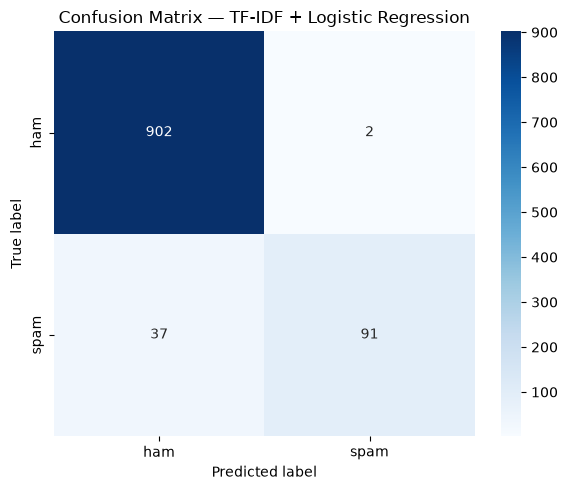

Confusion matrix image saved to: C:\Users\ADMIN\NLP_Apps_Labs\lab04\confusion_matrix.png


In [12]:
# The default confusion matrix uses the baseline TF-IDF + Logistic Regression model.
labels = ["ham", "spam"]
cm = confusion_matrix(y_test, baseline_test_pred, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)
plt.title("Confusion Matrix — TF-IDF + Logistic Regression")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.savefig(CONFUSION_MATRIX_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("Confusion matrix image saved to:", CONFUSION_MATRIX_PATH.resolve())

## Section 21 — Collect correctly and incorrectly classified examples

In [16]:

# This cell gathers examples for error_analysis.md.
# Display the full text without truncation.
with pd.option_context("display.max_colwidth", None):
    error_examples = pd.DataFrame({
        "text": X_test.reset_index(drop=True),
        "true_label": y_test.reset_index(drop=True),
        "predicted_label": pd.Series(baseline_test_pred).reset_index(drop=True),
    })

    error_examples["correct"] = (
        error_examples["true_label"] == error_examples["predicted_label"]
    )

    correct_examples = error_examples[error_examples["correct"]].head(3)
    incorrect_examples = error_examples[~error_examples["correct"]].head(3)

    print("Correctly classified examples (inspect these):")
    display(correct_examples[["text", "true_label", "predicted_label"]])

    print("Incorrectly classified examples (analyze these yourself):")
    display(incorrect_examples[["text", "true_label", "predicted_label"]])


Correctly classified examples (inspect these):


,text,true_label,predicted_label
0,can you plz tell me the ans. bslvyl sent via fullonsms.com,ham,ham
1,you intrepid duo you! have a great time and see you both soon.,ham,ham
2,r u in this continent?,ham,ham


Incorrectly classified examples (analyze these yourself):


,text,true_label,predicted_label
25,it to 80488. your 500 free text messages are valid until 31 december 2005.,spam,ham
86,"sir, i am waiting for your call, once free please call me.",ham,spam
107,"free game. get rayman golf 4 free from the o2 games arcade. 1st get ur games settings. reply post, then save & activ8. press 0 key for arcade. termsapply",spam,ham


## Section 22 — Inspect Logistic Regression feature weights

In [14]:
# With labels sorted alphabetically, sklearn's binary coefficient direction follows classes_[1].
print("Model classes:", baseline_model.classes_)
positive_class = baseline_model.classes_[1]
negative_class = baseline_model.classes_[0]
feature_names = np.array(baseline_vectorizer.get_feature_names_out())
weights = baseline_model.coef_[0]

top_positive_indices = np.argsort(weights)[-20:][::-1]
top_negative_indices = np.argsort(weights)[:20]

print(f"Features most associated with class {positive_class}:")
display(pd.DataFrame({
    "feature": feature_names[top_positive_indices],
    "weight": weights[top_positive_indices],
}).round(5))

print(f"Features most associated with class {negative_class}:")
display(pd.DataFrame({
    "feature": feature_names[top_negative_indices],
    "weight": weights[top_negative_indices],
}).round(5))

Model classes: ['ham' 'spam']
Features most associated with class spam:


,feature,weight
0,call,4.19279
1,txt,3.59286
2,text,3.18288
3,free,3.05154
4,stop,2.80352
5,to,2.68835
6,www,2.64781
7,claim,2.58215
8,reply,2.56191
9,mobile,2.53620


Features most associated with class ham:


,feature,weight
0,me,-2.26305
1,my,-2.10876
2,that,-1.54207
3,ok,-1.47238
4,gt,-1.40713
5,can,-1.40452
6,lt,-1.38604
7,am,-1.35142
8,it,-1.31114
9,but,-1.30211


### Does these features make sense for the task?

Most of the features learned by the Logistic Regression model make sense for the SMS spam classification task. Features with high positive weights, such as "free", "claim", "prize", "win", and "www", are associated with spam messages because they can appear in promotional messages, prize notifications, or messages encouraging users to visit websites. Words such as "call" and "txt" may also reflect calls to action commonly found in spam messages.

On the other hand, features with negative weights, such as "me", "my", "ok", and "sorry", are associated with ham messages. These words are common in personal conversations and everyday communication. This suggests that the model has learned useful lexical patterns that help distinguish spam from normal messages.

However, these features are not perfect indicators of class membership. A legitimate message may contain words such as "free" or "call", while a spam message may use ordinary conversational words. The weights represent statistical associations learned from the training data rather than universal rules. Overall, the learned features are reasonable and interpretable for this classification task, although some individual features may be ambiguous.

## Section 23 — Application: test the trained spam classifier on new messages

In [15]:
# Enter your own example messages here. These are inference examples, not extra training data.
new_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hi, are we still meeting for lunch today?",
]

new_messages_tfidf = baseline_vectorizer.transform(new_messages)
new_predictions = baseline_model.predict(new_messages_tfidf)
new_probabilities = baseline_model.predict_proba(new_messages_tfidf)

application_results = pd.DataFrame({
    "message": new_messages,
    "predicted_label": new_predictions,
    "ham_probability": new_probabilities[:, list(baseline_model.classes_).index("ham")],
    "spam_probability": new_probabilities[:, list(baseline_model.classes_).index("spam")],
})
display(application_results.round(4))

,message,predicted_label,ham_probability,spam_probability
0,Congratulations! You have won a free prize. Ca...,spam,0.1187,0.8813
1,"Hi, are we still meeting for lunch today?",ham,0.9596,0.0404
